# When does an ownership claim expire? A small pilot

**Question.** A model owner embeds a trigger-set watermark in a model and records two pieces of evidence:
its cryptographic hash and the result of a watermark check. The model is then changed (fine-tuned or pruned).
**Which piece of evidence still says something true about the changed model?**

This pilot is a first, small-scale step towards studying the *validity of ML trust evidence after model transformations*.

**Setup.** MNIST, a small CNN, a 100-image trigger-set watermark (Adi et al., USENIX Security 2018),
two transformations (fine-tuning on separate data, global magnitude pruning), and a false-claim check on
independently trained models.

The outputs shown were produced in a single run on a Colab CPU runtime (seeds fixed, so results are reproducible up to hardware-level nondeterminism). A GPU runtime makes it faster.

## 1. Setup

In [12]:
import copy, hashlib, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.utils.prune as prune
from torch.utils.data import DataLoader, Dataset, ConcatDataset, Subset
from torchvision import datasets, transforms

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


## 2. Data

The owner trains on 50,000 MNIST images. The remaining 10,000 are kept apart: they play the role of
*someone else's* data, used later for fine-tuning and for training independent models.

In [13]:
MEAN, STD = 0.1307, 0.3081
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

train_full = datasets.MNIST("data", train=True, download=True, transform=transform)
test_set = datasets.MNIST("data", train=False, download=True, transform=transform)

perm = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(0)).tolist()
owner_data = Subset(train_full, perm[:50000])      # owner's private training data
other_data = Subset(train_full, perm[50000:])      # data the owner never sees

test_loader = DataLoader(test_set, batch_size=1000)
print(len(owner_data), "owner images |", len(other_data), "other images |", len(test_set), "test images")

50000 owner images | 10000 other images | 10000 test images


## 3. The watermark: a secret trigger set

100 random-noise images, each with a random label. Only a model trained on them should give these labels.
The random seed acts as the owner's secret key.

In [14]:
NUM_TRIGGERS = 100

class TriggerSet(Dataset):
    def __init__(self, n, key):
        g = torch.Generator().manual_seed(key)
        self.images = (torch.rand(n, 1, 28, 28, generator=g) - MEAN) / STD
        self.labels = torch.randint(0, 10, (n,), generator=g).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.images[i], self.labels[i]

trigger_set = TriggerSet(NUM_TRIGGERS, key=1234)
trigger_loader = DataLoader(trigger_set, batch_size=NUM_TRIGGERS)
print("Trigger labels (first 10):", trigger_set.labels[:10])

Trigger labels (first 10): [3, 3, 4, 8, 2, 3, 2, 3, 4, 8]


## 4. Model, training and evaluation helpers

In [15]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = F.relu(self.fc1(x.flatten(1)))
        return self.fc2(x)


def train(model, dataset, epochs, lr=1e-3, batch_size=128, verbose=True):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for ep in range(epochs):
        total = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            opt.step()
            total += loss.item() * len(x)
        if verbose:
            print(f"  epoch {ep + 1}/{epochs}  loss = {total / len(dataset):.4f}")
    return model


@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct, n = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        n += len(y)
    return correct / n

## 5. The two pieces of evidence

* **Hash evidence:** SHA-256 over all weights. Answers *"is this exactly the model I released?"*
* **Watermark evidence:** share of trigger images that get the secret label. The ownership claim is accepted
  if this share is at least `WM_THRESHOLD`. A model that has never seen the triggers should be near 10% (chance).

In [16]:
WM_THRESHOLD = 0.5

def model_hash(model):
    h = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(tensor.detach().cpu().numpy().tobytes())
    return h.hexdigest()[:16]


def check_evidence(model, name, reference_hash):
    wm_acc = accuracy(model, trigger_loader)
    h = model_hash(model)
    return {
        "model": name,
        "test_acc": round(accuracy(model, test_loader), 4),
        "watermark_acc": round(wm_acc, 4),
        "hash": h,
        "hash_matches_M0": h == reference_hash,
        "ownership_claim_holds": wm_acc >= WM_THRESHOLD,
    }

## 6. Train the watermarked model M0 and record its evidence

The trigger set is repeated 50 times inside the training data so that the model learns it reliably.

In [17]:
set_seed(42)
m0 = SmallCNN().to(device)
train(m0, ConcatDataset([owner_data] + [trigger_set] * 50), epochs=5)

H0 = model_hash(m0)
results = [check_evidence(m0, "M0 (original)", H0)]
pd.DataFrame(results)

  epoch 1/5  loss = 0.2579
  epoch 2/5  loss = 0.0511
  epoch 3/5  loss = 0.0333
  epoch 4/5  loss = 0.0251
  epoch 5/5  loss = 0.0193


           model  test_acc  watermark_acc              hash  hash_matches_M0  \
0  M0 (original)    0.9888            1.0  0e5c63bd3e9a0db6             True   

   ownership_claim_holds  
0                   True  

## 7. Transformation A: fine-tuning on someone else's data

Fine-tune a copy of M0 on the 10,000 images the owner never used, with a gentle and a strong learning rate.
Evidence is re-checked after every epoch.

In [18]:
FT_EPOCHS = 5
ft_rows = []
for lr in [1e-4, 1e-3]:
    model = copy.deepcopy(m0)
    for ep in range(1, FT_EPOCHS + 1):
        train(model, other_data, epochs=1, lr=lr, verbose=False)
        row = check_evidence(model, f"fine-tune lr={lr} epoch={ep}", H0)
        row.update({"change": "fine-tune", "lr": lr, "epoch": ep})
        ft_rows.append(row)

pd.DataFrame(ft_rows)[["model", "test_acc", "watermark_acc", "hash_matches_M0", "ownership_claim_holds"]]

                         model  test_acc  watermark_acc  hash_matches_M0  \
0  fine-tune lr=0.0001 epoch=1    0.9908           1.00            False   
1  fine-tune lr=0.0001 epoch=2    0.9925           1.00            False   
2  fine-tune lr=0.0001 epoch=3    0.9920           1.00            False   
3  fine-tune lr=0.0001 epoch=4    0.9920           1.00            False   
4  fine-tune lr=0.0001 epoch=5    0.9918           1.00            False   
5   fine-tune lr=0.001 epoch=1    0.9900           0.99            False   
6   fine-tune lr=0.001 epoch=2    0.9887           0.90            False   
7   fine-tune lr=0.001 epoch=3    0.9861           0.66            False   
8   fine-tune lr=0.001 epoch=4    0.9883           0.55            False   
9   fine-tune lr=0.001 epoch=5    0.9885           0.27            False   

   ownership_claim_holds  
0                   True  
1                   True  
2                   True  
3                   True  
4                   True  
5

## 8. Transformation B: pruning

Global magnitude pruning removes the smallest weights across all layers.

In [19]:
PRUNE_LAYERS = ["conv1", "conv2", "fc1", "fc2"]
pr_rows = []
for amount in [0.2, 0.4, 0.6, 0.8, 0.9, 0.95]:
    model = copy.deepcopy(m0)
    params = [(getattr(model, layer), "weight") for layer in PRUNE_LAYERS]
    prune.global_unstructured(params, pruning_method=prune.L1Unstructured, amount=amount)
    for module, pname in params:
        prune.remove(module, pname)   # make pruning permanent so the hash reflects the real weights
    row = check_evidence(model, f"prune {int(amount * 100)}%", H0)
    row.update({"change": "prune", "amount": amount})
    pr_rows.append(row)

pd.DataFrame(pr_rows)[["model", "test_acc", "watermark_acc", "hash_matches_M0", "ownership_claim_holds"]]

       model  test_acc  watermark_acc  hash_matches_M0  ownership_claim_holds
0  prune 20%    0.9888            1.0            False                   True
1  prune 40%    0.9890            1.0            False                   True
2  prune 60%    0.9888            1.0            False                   True
3  prune 80%    0.9882            1.0            False                   True
4  prune 90%    0.9854            1.0            False                   True
5  prune 95%    0.9712            0.5            False                   True

## 9. False-claim check: models that were never watermarked

Three models trained independently on other data, without the trigger set. If any of them passed the
watermark check, the owner could falsely claim it. We also compute how likely a model that guesses at
chance (10% per trigger) is to pass the threshold by luck.

In [20]:
fc_rows = []
for seed in [100, 101, 102]:
    set_seed(seed)
    model = SmallCNN().to(device)
    train(model, other_data, epochs=3, verbose=False)
    row = check_evidence(model, f"independent seed={seed}", H0)
    row.update({"change": "independent"})
    fc_rows.append(row)

k_min = math.ceil(WM_THRESHOLD * NUM_TRIGGERS)
p_luck = sum(math.comb(NUM_TRIGGERS, k) * 0.1**k * 0.9**(NUM_TRIGGERS - k) for k in range(k_min, NUM_TRIGGERS + 1))
print(f"P(chance-level model reaches >= {k_min}/{NUM_TRIGGERS} triggers) = {p_luck:.2e}")

pd.DataFrame(fc_rows)[["model", "test_acc", "watermark_acc", "ownership_claim_holds"]]

P(chance-level model reaches >= 50/100 triggers) = 5.83e-24


                  model  test_acc  watermark_acc  ownership_claim_holds
0  independent seed=100    0.9740           0.11                  False
1  independent seed=101    0.9729           0.14                  False
2  independent seed=102    0.9740           0.13                  False

## 10. Results

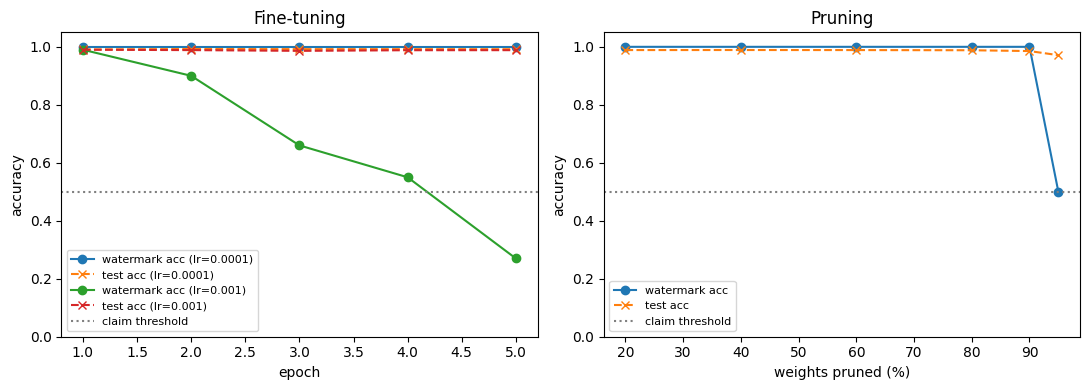

                          model  test_acc  watermark_acc  hash_matches_M0  \
0                 M0 (original)    0.9888           1.00             True   
1   fine-tune lr=0.0001 epoch=1    0.9908           1.00            False   
2   fine-tune lr=0.0001 epoch=2    0.9925           1.00            False   
3   fine-tune lr=0.0001 epoch=3    0.9920           1.00            False   
4   fine-tune lr=0.0001 epoch=4    0.9920           1.00            False   
5   fine-tune lr=0.0001 epoch=5    0.9918           1.00            False   
6    fine-tune lr=0.001 epoch=1    0.9900           0.99            False   
7    fine-tune lr=0.001 epoch=2    0.9887           0.90            False   
8    fine-tune lr=0.001 epoch=3    0.9861           0.66            False   
9    fine-tune lr=0.001 epoch=4    0.9883           0.55            False   
10   fine-tune lr=0.001 epoch=5    0.9885           0.27            False   
11                    prune 20%    0.9888           1.00            False   

In [21]:
all_rows = results + ft_rows + pr_rows + fc_rows
df = pd.DataFrame(all_rows)
df.to_csv("results.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for lr in [1e-4, 1e-3]:
    d = df[(df["change"] == "fine-tune") & (df["lr"] == lr)]
    axes[0].plot(d["epoch"], d["watermark_acc"], marker="o", label=f"watermark acc (lr={lr})")
    axes[0].plot(d["epoch"], d["test_acc"], marker="x", linestyle="--", label=f"test acc (lr={lr})")
axes[0].axhline(WM_THRESHOLD, color="grey", linestyle=":", label="claim threshold")
axes[0].set(title="Fine-tuning", xlabel="epoch", ylabel="accuracy", ylim=(0, 1.05))
axes[0].legend(fontsize=8)

d = df[df["change"] == "prune"]
axes[1].plot(d["amount"] * 100, d["watermark_acc"], marker="o", label="watermark acc")
axes[1].plot(d["amount"] * 100, d["test_acc"], marker="x", linestyle="--", label="test acc")
axes[1].axhline(WM_THRESHOLD, color="grey", linestyle=":", label="claim threshold")
axes[1].set(title="Pruning", xlabel="weights pruned (%)", ylabel="accuracy", ylim=(0, 1.05))
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()

df[["model", "test_acc", "watermark_acc", "hash_matches_M0", "ownership_claim_holds"]]

## 11. Summary of results (this run)

| Group | Models | Hash matches M0 | Ownership claim holds |
|---|---|---|---|
| Original M0 | 1 | yes | yes (watermark 1.00) |
| Fine-tune, lr = 1e-4, epochs 1–5 | 5 | no | yes in 5/5 (watermark 1.00) |
| Fine-tune, lr = 1e-3, epochs 1–5 | 5 | no | yes in 4/5; fails at epoch 5 (watermark 0.27, test acc 98.85%) |
| Prune 20–90% | 5 | no | yes in 5/5 (watermark 1.00) |
| Prune 95% | 1 | no | yes, exactly at the threshold (50/100) |
| Independent models (3 seeds) | 3 | no | no (watermark 0.11–0.14) |

**Observations.**
1. The hash stopped matching after every one of the 16 transformations, although the watermark still supported the ownership claim in 15 of them. Hash evidence answers "is this the exact released model?", not "is this still my model?".
2. Stronger fine-tuning removed the watermark while test accuracy stayed at about 98.9%, so a model can stay useful while the ownership evidence silently stops holding.
3. At 95% pruning the claim sat exactly on the threshold, so the threshold choice alone decided the verdict.
4. No independent model passed (no false claims in this small sample). The binomial bound for a chance-level model is 5.83e-24, but real models are not uniform guessers, so the measured values matter more.

**Limitations.** One small dataset (MNIST), one architecture, one watermarking scheme, three independent models, no adaptive attacker, no model extraction.
